# Air Quality Index — Tree-based Regression

Small AQI regression on the UCI Air Quality dataset (hourly sensor readings in an Italian city for ~1 year). Target is the CO concentration (a proxy AQI signal). Sensors have known broken stretches encoded as -200; those rows have to be dropped.

Data: UCI Air Quality (id 360, De Vito et al., CC BY 4.0), 9,357 hourly averages from a gas multisensor device on a road in an Italian city, March 2004 to February 2005, with reference analyzer readings. The loader downloads the UCI zip on first run.

In [1]:
import numpy as np, pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, r2_score

DATA = Path('../../data/air_quality'); DATA.mkdir(parents=True, exist_ok=True)
CSV = DATA / 'AirQualityUCI.csv'

In [2]:
import io, urllib.request, zipfile
if not CSV.exists():
    url = 'https://archive.ics.uci.edu/static/public/360/air+quality.zip'
    zipfile.ZipFile(io.BytesIO(urllib.request.urlopen(url).read())).extract('AirQualityUCI.csv', DATA)
# UCI's CSV uses ; as separator and , as decimal
df = pd.read_csv(CSV, sep=';', decimal=',')
df = df.dropna(how='all').dropna(axis=1, how='all')
print('loaded UCI Air Quality file', df.shape)

loaded UCI Air Quality file (9357, 15)


In [3]:
# -200 is UCI's missing-data sentinel. Treat as NaN, then drop rows where the target is gone.
df = df.replace(-200, np.nan)
df = df.dropna(subset=['CO(GT)']).copy()
if 'hour' not in df.columns:
    if 'Time' in df.columns:
        df['hour'] = df['Time'].astype(str).str.slice(0, 2).astype(int, errors='ignore')
    else:
        df['hour'] = 12
print('rows after cleaning', df.shape)

rows after cleaning (7674, 16)


## EDA

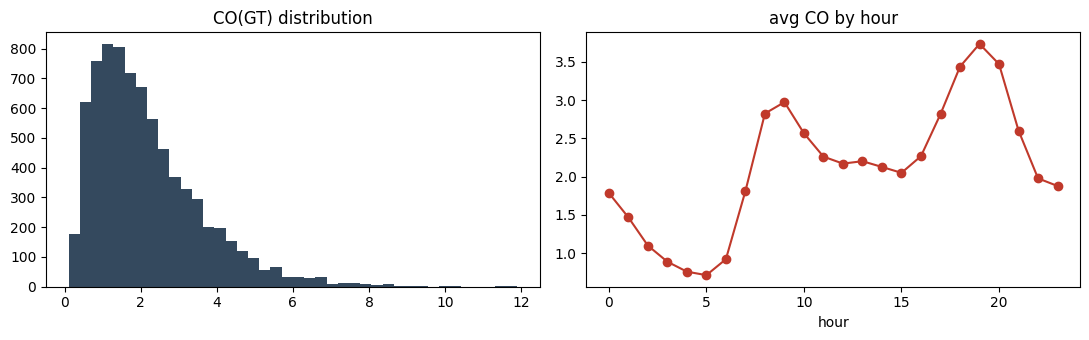

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].hist(df['CO(GT)'], bins=40, color='#34495e'); ax[0].set_title('CO(GT) distribution')
df.groupby('hour')['CO(GT)'].mean().plot(ax=ax[1], marker='o', color='#c0392b')
ax[1].set_title('avg CO by hour'); plt.tight_layout(); plt.show()

In [5]:
FEATURES = [c for c in df.columns if c not in ['CO(GT)', 'Date', 'Time']]
FEATURES = [c for c in FEATURES if np.issubdtype(df[c].dtype, np.number)]
X = df[FEATURES].fillna(df[FEATURES].median()).values
y = df['CO(GT)'].values

X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=42)
model = GradientBoostingRegressor(n_estimators=300, max_depth=4, learning_rate=0.05, random_state=42)
model.fit(X_tr, y_tr)
pred = model.predict(X_te)
print(f'MAE  = {mean_absolute_error(y_te, pred):.3f}')
print(f'R^2  = {r2_score(y_te, pred):.3f}')

MAE  = 0.233
R^2  = 0.935


In [6]:
imp = pd.Series(model.feature_importances_, index=FEATURES).sort_values(ascending=False)
imp

PT08.S2(NMHC)    0.558733
C6H6(GT)         0.243637
NOx(GT)          0.090886
PT08.S1(CO)      0.045783
hour             0.015633
NO2(GT)          0.012699
T                0.010057
PT08.S4(NO2)     0.005453
PT08.S5(O3)      0.004402
AH               0.003833
PT08.S3(NOx)     0.003242
RH               0.003238
NMHC(GT)         0.002405
dtype: float64

## Wrap-up

On the real UCI file (7,674 hours with a reference CO reading), gradient boosting predicts CO with MAE 0.233 mg/m³ and R² 0.935 on a random 20% holdout. That looks great, but look at what it leans on: the tin-oxide sensor `PT08.S2(NMHC)` first, then `C6H6(GT)` and `NOx(GT)`, which are the *reference analyzer* readings for other pollutants. Those come from the same certified station that measures CO, so in a real "replace the expensive analyzer with cheap sensors" setting they wouldn't be available. The honest version of this model uses only the `PT08.*` sensor columns plus temperature and humidity.

If I were taking this further I'd:
- Drop the `(GT)` reference columns from the features, for the reason above.
- Treat the time-series structure properly (random split leaks neighbouring hours; a block split by day or week is more honest). The UCI paper's real problem is sensor drift over the year, which only a time-ordered split would show.
- Replace median-imputation on the broken-sensor stretches with a forward-fill or a small interpolation. Median imputation flattens the daily pattern.
- See whether a small neural network can match this. That's project 85.